# 03b — Baseline Score Analysis (Full Period)

**Goal:** analyse the scores of the two baseline models from prior work (Helm 2025; Steiner et al., RAMS 2026) over the **full period** (Jun 2024 – Jun 2025), not only the test period they were evaluated on: where they raise alarms, how their scores shift between train and test, and where false-alarm clusters sit. This is the problem analysis that motivates the thesis (many false alarms, drift).

- **Random Forest (supervised):** probability that a failure is running or starts within 6.2 h, per 350 s window
- **LSTM autoencoder (unsupervised):** reconstruction error per 1,402 s sequence

The models are **applied, not trained** here. They come from `outputs/supervised/rf_model.joblib` and `outputs/unsupervised/lstm_ae_model.pt` (Helm's best parameters; produced before NB02 was split). After NB02b is run in Phase 2, re-run this notebook.

**This notebook is not an input to the clustering.** NB04 uses only the feature windows (explored in NB03a).

**Sections:**
1. Data loading (RF scores, LSTM-AE scores, failure events)
2. Full-period score timeline
3. Score distributions — train vs test, by month
4. Score hotspots — sustained high-score periods
5. LSTM-AE input checks (standardization, near-constant channels)
6. Daily and time-of-day RF scores

In [1]:
import sys, os, glob, gc, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
import seaborn as sns
from scipy import stats
import joblib
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import warnings
warnings.filterwarnings('ignore')

sys.path.insert(0, os.path.abspath('..'))
ROOT = os.path.abspath('..')
OUT_DIR = os.path.join(ROOT, 'outputs')
NB03B_OUT = os.path.join(OUT_DIR, 'nb03b_artifacts')
os.makedirs(NB03B_OUT, exist_ok=True)

# Constants
WINDOW_S = 350
HORIZON_S = 22326
SEQ_WINDOW_S = 1402
SUBSAMPLE = 4
seq_len_sub = SEQ_WINDOW_S // SUBSAMPLE  # 350
n_channels = 95
TS_COL = 'TIMESTAMP'
FAIL_COL = 'TRAIN_IS_IN_FAILURE'
FAIL_TYPE = 'TRAIN_FAILURE_TYPE'
MAINT_COL = 'TRAIN_IS_IN_MAINTENANCE'
SPLIT_DATE = pd.Timestamp('2025-02-12')

print('Setup complete')

Setup complete


## 1. Data Loading — Full Period

Load RF predictions on both train and test windows, plus LSTM-AE scores on full period.

In [2]:
# ── Load supervised data and RF model ──
saved = joblib.load(os.path.join(OUT_DIR, 'supervised', 'rf_model.joblib'))
rf_model = saved['model']
RF_THR = saved['threshold']

train_sup = pd.read_parquet(os.path.join(OUT_DIR, 'supervised', 'train.parquet'))
test_sup = pd.read_parquet(os.path.join(OUT_DIR, 'supervised', 'test.parquet'))

train_sup['window_end'] = pd.to_datetime(train_sup['window_end'])
test_sup['window_end'] = pd.to_datetime(test_sup['window_end'])

feature_cols = [c for c in train_sup.columns if c not in {'timestamp', 'window_end', 'label'}]

# Predict RF probabilities on both splits
train_sup['prob'] = rf_model.predict_proba(train_sup[feature_cols])[:, 1]
train_sup['pred'] = (train_sup['prob'] >= RF_THR).astype(int)
train_sup['fail'] = train_sup['label']
train_sup['split'] = 'train'  # period = source file (official MetroAT split, as in NB02a and NB04)

test_sup['prob'] = rf_model.predict_proba(test_sup[feature_cols])[:, 1]
test_sup['pred'] = (test_sup['prob'] >= RF_THR).astype(int)
test_sup['fail'] = test_sup['label']
test_sup['split'] = 'test'

# Combine
rf_all = pd.concat([
    train_sup[['window_end', 'prob', 'pred', 'fail', 'split']],
    test_sup[['window_end', 'prob', 'pred', 'fail', 'split']]
]).sort_values('window_end').reset_index(drop=True)


del train_sup, test_sup; gc.collect()

print(f'RF full period: {len(rf_all):,} windows')
print(f'  Train: {(rf_all["split"]=="train").sum():,} | Test: {(rf_all["split"]=="test").sum():,}')
print(f'  Date range: {rf_all["window_end"].min()} to {rf_all["window_end"].max()}')
print(f'  Failure windows: {rf_all["fail"].sum():,} ({100*rf_all["fail"].mean():.2f}%)')
print(f'  RF threshold: {RF_THR:.3f}')

RF full period: 64,522 windows
  Train: 41,375 | Test: 23,147
  Date range: 2024-06-01 04:41:40 to 2025-07-01 00:04:10
  Failure windows: 1,202 (1.86%)
  RF threshold: 0.200


In [3]:
# ── Load or compute LSTM-AE scores for full period ──
cache_path = os.path.join(OUT_DIR, 'unsupervised', 'full_period_lstmae_scores.parquet')

if os.path.exists(cache_path):
    ae_all = pd.read_parquet(cache_path)
    ae_all['window_end'] = pd.to_datetime(ae_all['window_end'])
    print(f'Loaded cached LSTM-AE scores: {len(ae_all):,} sequences')
else:
    print('Computing LSTM-AE scores for full period (this takes a few minutes)...')
    
    # Load metadata and model
    with open(os.path.join(OUT_DIR, 'unsupervised', 'metadata.json')) as f:
        meta = json.load(f)
    UNSUP_CHANNELS = meta['channels']
    channel_stats = meta['channel_stats']

    class LSTMAutoencoder(nn.Module):
        def __init__(self, nc, hd):
            super().__init__()
            self.encoder = nn.LSTM(nc, hd, batch_first=True)
            self.decoder = nn.LSTM(hd, hd, batch_first=True)
            self.output_layer = nn.Linear(hd, nc)
        def forward(self, x):
            _, (h, c) = self.encoder(x)
            dec_in = h.squeeze(0).unsqueeze(1).repeat(1, x.size(1), 1)
            dec_out, _ = self.decoder(dec_in, (h, c))
            return self.output_layer(dec_out)

    ae_model = LSTMAutoencoder(n_channels, 64)
    ae_model.load_state_dict(torch.load(
        os.path.join(OUT_DIR, 'unsupervised', 'lstm_ae_model.pt'), weights_only=True))
    ae_model.eval()

    def score_split(data_glob, split_name):
        files = sorted(glob.glob(data_glob, recursive=True))
        unsup_cols = [TS_COL, FAIL_COL, MAINT_COL] + UNSUP_CHANNELS
        chunks = []
        for f in files:
            df = pd.read_parquet(f)
            avail = [c for c in unsup_cols if c in df.columns]
            chunks.append(df[avail])
            del df
        raw = pd.concat(chunks, ignore_index=True)
        del chunks; gc.collect()
        raw[TS_COL] = pd.to_datetime(raw[TS_COL])
        raw.sort_values(TS_COL, inplace=True)
        raw.reset_index(drop=True, inplace=True)
        clean = raw[~raw[MAINT_COL].astype(bool)].copy()
        del raw; gc.collect()
        for c in UNSUP_CHANNELS:
            clean[c] = (clean[c] - channel_stats[c]['mean']) / channel_stats[c]['std']
        clean = clean.set_index(TS_COL).sort_index()
        resampler = clean.resample(f'{SEQ_WINDOW_S}s', origin='epoch')

        times, labels, seqs = [], [], []
        for ws, group in resampler:
            if len(group) < int(SEQ_WINDOW_S * 0.8):
                continue
            vals = group[UNSUP_CHANNELS].values
            if len(vals) >= SEQ_WINDOW_S:
                sub = vals[::SUBSAMPLE][:seq_len_sub]
            else:
                x_old = np.linspace(0, 1, len(vals))
                x_new = np.linspace(0, 1, SEQ_WINDOW_S)
                full = np.zeros((SEQ_WINDOW_S, n_channels), dtype=np.float32)
                for ch in range(n_channels):
                    full[:, ch] = np.interp(x_new, x_old, vals[:, ch])
                sub = full[::SUBSAMPLE][:seq_len_sub]
            if len(sub) < seq_len_sub:
                sub = np.vstack([sub, np.zeros((seq_len_sub - len(sub), n_channels), dtype=np.float32)])
            seqs.append(np.nan_to_num(sub, 0.0).astype(np.float32))
            times.append(ws + pd.Timedelta(seconds=SEQ_WINDOW_S))
            has_fail = group[FAIL_COL].astype(bool).any() if FAIL_COL in group.columns else False
            labels.append(int(has_fail))
        del clean; gc.collect()

        seqs_arr = np.array(seqs, dtype=np.float32)
        loader = DataLoader(TensorDataset(torch.FloatTensor(seqs_arr), torch.FloatTensor(seqs_arr)), batch_size=128)
        errors = []
        with torch.no_grad():
            for xb, _ in loader:
                recon = ae_model(xb)
                errors.append(((xb - recon) ** 2).mean(dim=(1, 2)).numpy())
        scores = np.concatenate(errors)
        result = pd.DataFrame({'window_end': times, 'score': scores, 'fail': labels, 'split': split_name})
        print(f'  {split_name}: {len(result):,} sequences ({result["fail"].sum()} failure)')
        return result

    ae_train = score_split(os.path.join(ROOT, 'train', '**', '*.parquet'), 'train')
    ae_test = score_split(os.path.join(ROOT, 'test', '**', '*.parquet'), 'test')
    ae_all = pd.concat([ae_train, ae_test], ignore_index=True)
    ae_all['window_end'] = pd.to_datetime(ae_all['window_end'])
    ae_all = ae_all.sort_values('window_end').reset_index(drop=True)
    ae_all.to_parquet(cache_path, index=False)
    print(f'Saved cache: {cache_path}')
    del ae_train, ae_test, ae_model; gc.collect()

print(f'\nLSTM-AE full period: {len(ae_all):,} sequences')
print(f'  Train: {(ae_all["split"]=="train").sum():,} | Test: {(ae_all["split"]=="test").sum():,}')
print(f'  Date range: {ae_all["window_end"].min()} to {ae_all["window_end"].max()}')
print(f'  Failure sequences: {ae_all["fail"].sum()} ({100*ae_all["fail"].mean():.2f}%)')

Loaded cached LSTM-AE scores: 15,246 sequences

LSTM-AE full period: 15,246 sequences
  Train: 9,872 | Test: 5,374
  Date range: 2024-06-01 05:11:10 to 2025-06-30 23:58:48
  Failure sequences: 111 (0.73%)


In [4]:
# ── Extract ALL failure events (train+test) from raw data ──
all_files = sorted(
    glob.glob(os.path.join(ROOT, 'train', '**', '*.parquet'), recursive=True) +
    glob.glob(os.path.join(ROOT, 'test', '**', '*.parquet'), recursive=True)
)
chunks = []
for f in all_files:
    df = pd.read_parquet(f, columns=[TS_COL, FAIL_COL, FAIL_TYPE, MAINT_COL])
    chunks.append(df)
raw_meta = pd.concat(chunks, ignore_index=True)
del chunks; gc.collect()

raw_meta[TS_COL] = pd.to_datetime(raw_meta[TS_COL])
raw_meta.sort_values(TS_COL, inplace=True)

# Extract failure event blocks
mask = raw_meta[FAIL_COL].astype(bool)
grp = (mask != mask.shift()).cumsum()
fail_events = (
    raw_meta[mask].groupby(grp[mask])
    .agg(start=(TS_COL, 'min'), end=(TS_COL, 'max'),
         event_type=(FAIL_TYPE, 'first'), n_rows=(TS_COL, 'count'))
    .reset_index(drop=True)
)

# Merge nearby events of same type (within 1h)
merged = []
for _, row in fail_events.iterrows():
    if merged and row['event_type'] == merged[-1]['event_type'] and \
       (row['start'] - merged[-1]['end']).total_seconds() < 3600:
        merged[-1]['end'] = row['end']
        merged[-1]['n_rows'] += row['n_rows']
    else:
        merged.append(dict(row))
fail_events_all = pd.DataFrame(merged)
fail_events_all['duration_min'] = (fail_events_all['end'] - fail_events_all['start']).dt.total_seconds() / 60
fail_events_all['period'] = fail_events_all['start'].apply(lambda x: 'train' if x < SPLIT_DATE else 'test')

# Also extract maintenance periods
maint_mask = raw_meta[MAINT_COL].astype(bool)
maint_grp = (maint_mask != maint_mask.shift()).cumsum()
maint_events = (
    raw_meta[maint_mask].groupby(maint_grp[maint_mask])
    .agg(start=(TS_COL, 'min'), end=(TS_COL, 'max'), n_rows=(TS_COL, 'count'))
    .reset_index(drop=True)
)
maint_events['duration_min'] = (maint_events['end'] - maint_events['start']).dt.total_seconds() / 60

del raw_meta; gc.collect()

print(f'All failure events (merged): {len(fail_events_all)}')
print(f'  Train: {(fail_events_all["period"]=="train").sum()} | Test: {(fail_events_all["period"]=="test").sum()}')
print(f'Maintenance periods: {len(maint_events)}')
print(f'\nFailure events:')
print(fail_events_all[['start', 'end', 'event_type', 'duration_min', 'period']].to_string(index=False))

All failure events (merged): 21
  Train: 10 | Test: 11
Maintenance periods: 18

Failure events:
              start                 end                event_type  duration_min period
2024-06-27 15:47:30 2024-06-27 17:52:28      Brake System Failure    124.966667  train
2024-08-19 10:37:51 2024-08-19 11:05:44      Brake System Failure     27.883333  train
2024-08-27 15:58:43 2024-08-28 21:29:25   Leveling System Failure   1770.700000  train
2024-09-03 05:04:00 2024-09-03 07:33:36      Brake System Failure    149.600000  train
2024-09-22 05:49:43 2024-09-22 08:14:45      Brake System Failure    145.033333  train
2024-10-06 02:04:15 2024-10-08 09:15:36      Brake System Failure   3311.350000  train
2024-10-10 11:19:48 2024-10-10 15:35:49      Brake System Failure    256.016667  train
2024-10-31 15:08:06 2024-10-31 18:26:02 Compressor Module Failure    197.933333  train
2024-12-14 18:56:40 2024-12-14 23:31:05      Brake System Failure    274.416667  train
2025-01-21 06:11:15 2025-01-21 09:

## 2. Full-Period Anomaly Timeline

RF probability and LSTM-AE reconstruction error across the entire dataset (Jun 2024 – Jun 2025), with failure events and train/test split marked.

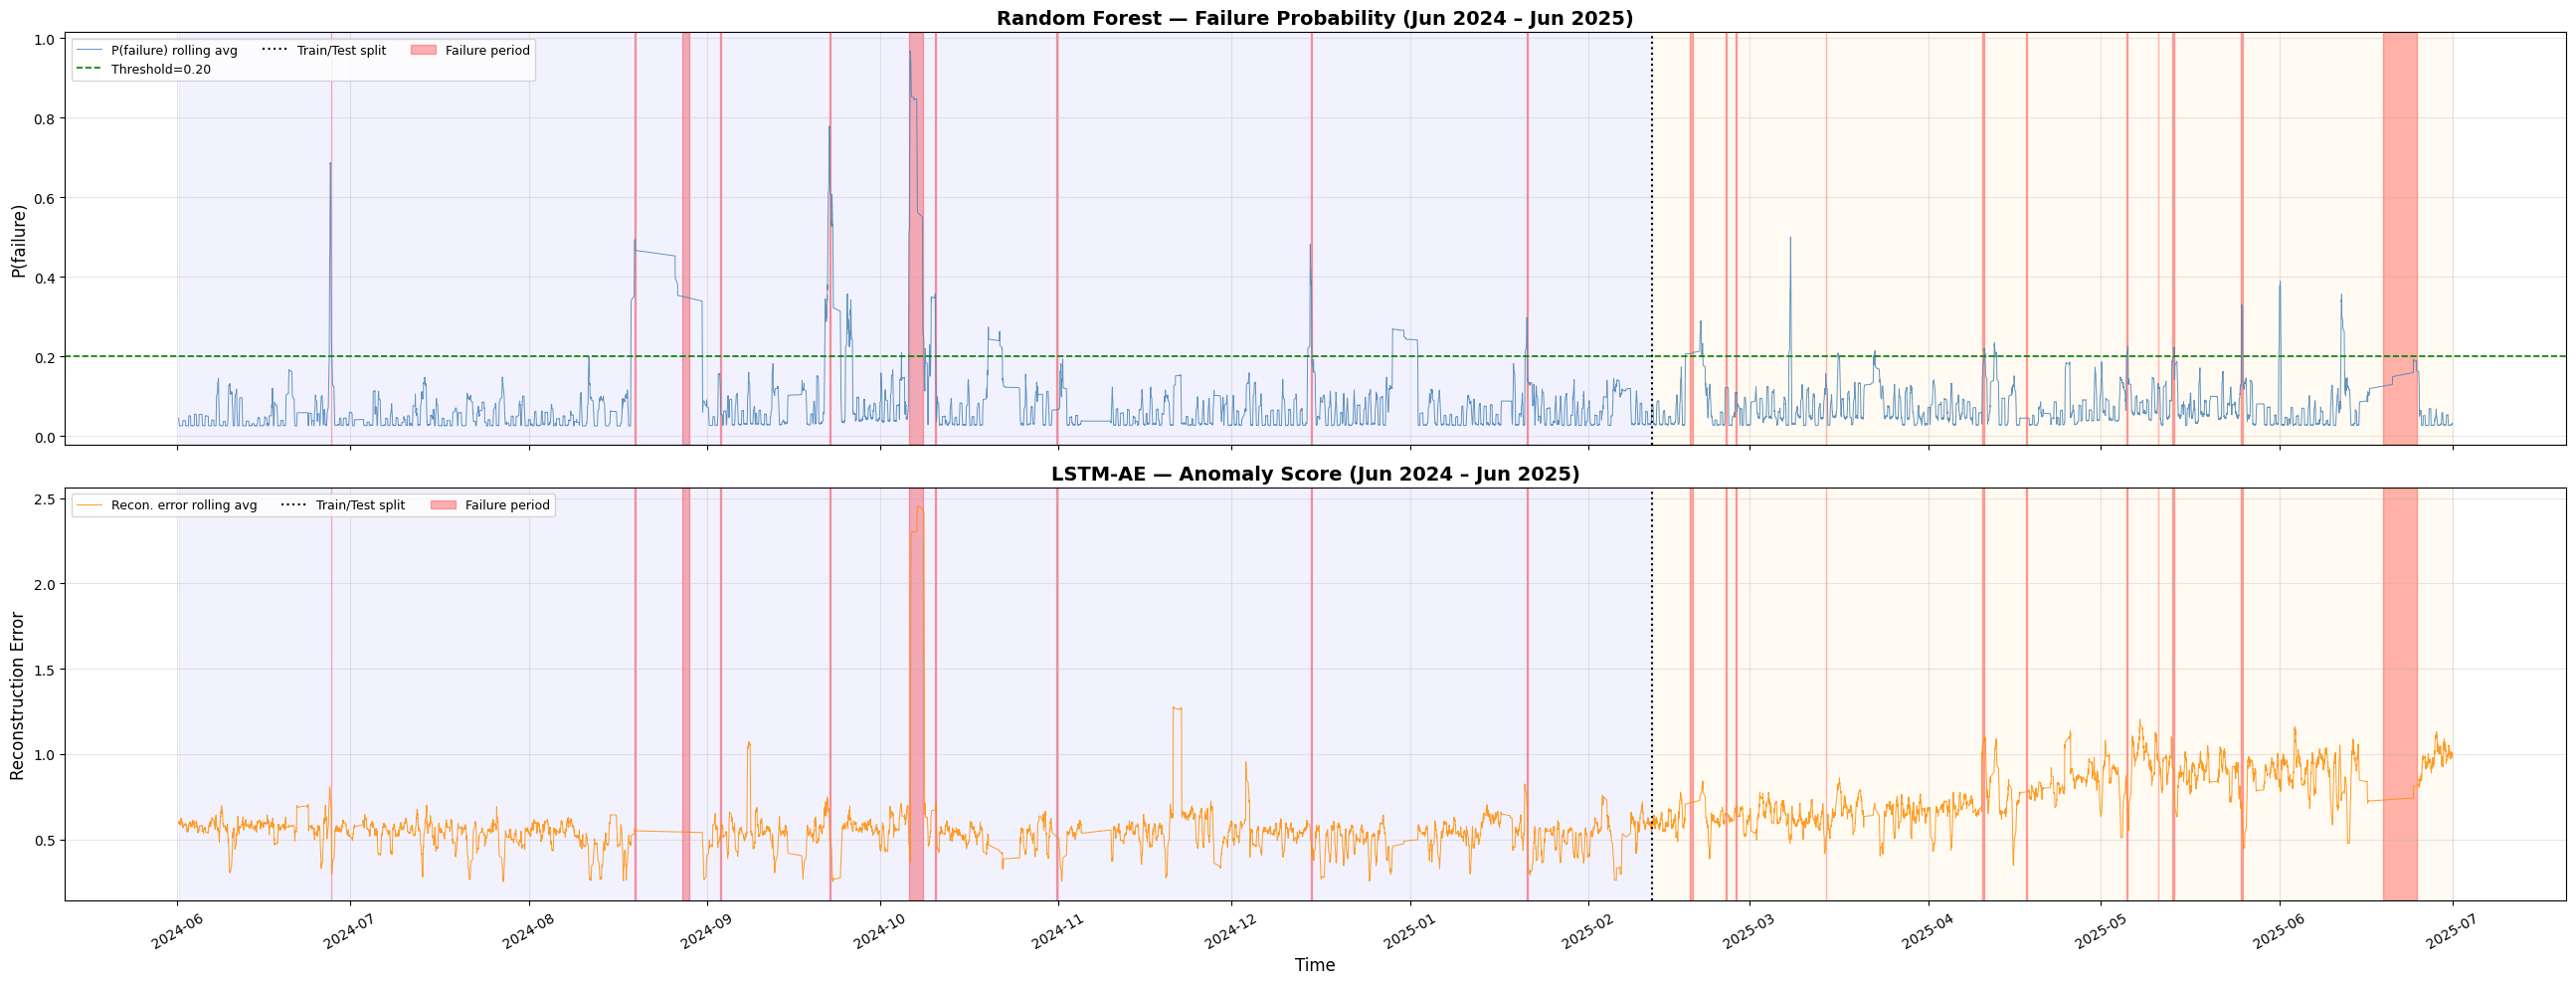

Saved anomaly_timeline_full.png


In [5]:
# Rolling averages
rf_all_ts = rf_all.set_index('window_end').sort_index()
ae_all_ts = ae_all.set_index('window_end').sort_index()

rf_roll = rf_all_ts['prob'].rolling(50, center=True, min_periods=1).mean()
ae_roll = ae_all_ts['score'].rolling(20, center=True, min_periods=1).mean()

fig, axes = plt.subplots(2, 1, figsize=(26, 10), sharex=True)

# RF panel
ax = axes[0]
ax.plot(rf_roll.index, rf_roll.values, color='steelblue', linewidth=0.7, alpha=0.85, label='P(failure) rolling avg')
ax.axhline(y=RF_THR, color='green', linestyle='--', linewidth=1.2, label=f'Threshold={RF_THR:.2f}')
ax.axvline(x=SPLIT_DATE, color='black', linestyle=':', linewidth=1.5, label='Train/Test split')
for i, (_, ev) in enumerate(fail_events_all.iterrows()):
    ax.axvspan(ev['start'], ev['end'], alpha=0.3, color='red', label='Failure period' if i == 0 else '_')
ax.axvspan(rf_all_ts.index.min(), SPLIT_DATE, alpha=0.05, color='blue')
ax.axvspan(SPLIT_DATE, rf_all_ts.index.max(), alpha=0.05, color='orange')
ax.set_ylabel('P(failure)', fontsize=12)
ax.set_title('Random Forest — Failure Probability (Jun 2024 – Jun 2025)', fontsize=14, fontweight='bold')
ax.legend(loc='upper left', fontsize=9, ncol=3)
ax.grid(True, alpha=0.3)

# LSTM-AE panel
ax = axes[1]
ax.plot(ae_roll.index, ae_roll.values, color='darkorange', linewidth=0.7, alpha=0.85, label='Recon. error rolling avg')
ax.axvline(x=SPLIT_DATE, color='black', linestyle=':', linewidth=1.5, label='Train/Test split')
for i, (_, ev) in enumerate(fail_events_all.iterrows()):
    ax.axvspan(ev['start'], ev['end'], alpha=0.3, color='red', label='Failure period' if i == 0 else '_')
ax.axvspan(ae_all_ts.index.min(), SPLIT_DATE, alpha=0.05, color='blue')
ax.axvspan(SPLIT_DATE, ae_all_ts.index.max(), alpha=0.05, color='orange')
ax.set_ylabel('Reconstruction Error', fontsize=12)
ax.set_title('LSTM-AE — Anomaly Score (Jun 2024 – Jun 2025)', fontsize=14, fontweight='bold')
ax.set_xlabel('Time', fontsize=12)
ax.legend(loc='upper left', fontsize=9, ncol=3)
ax.grid(True, alpha=0.3)

axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
axes[-1].xaxis.set_major_locator(mdates.MonthLocator())
plt.xticks(rotation=30, fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(NB03B_OUT, 'anomaly_timeline_full.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved anomaly_timeline_full.png')

## 3. Score Distributions — Train vs Test, by Month

How do anomaly scores differ between train and test? Do they shift over time (concept drift)?

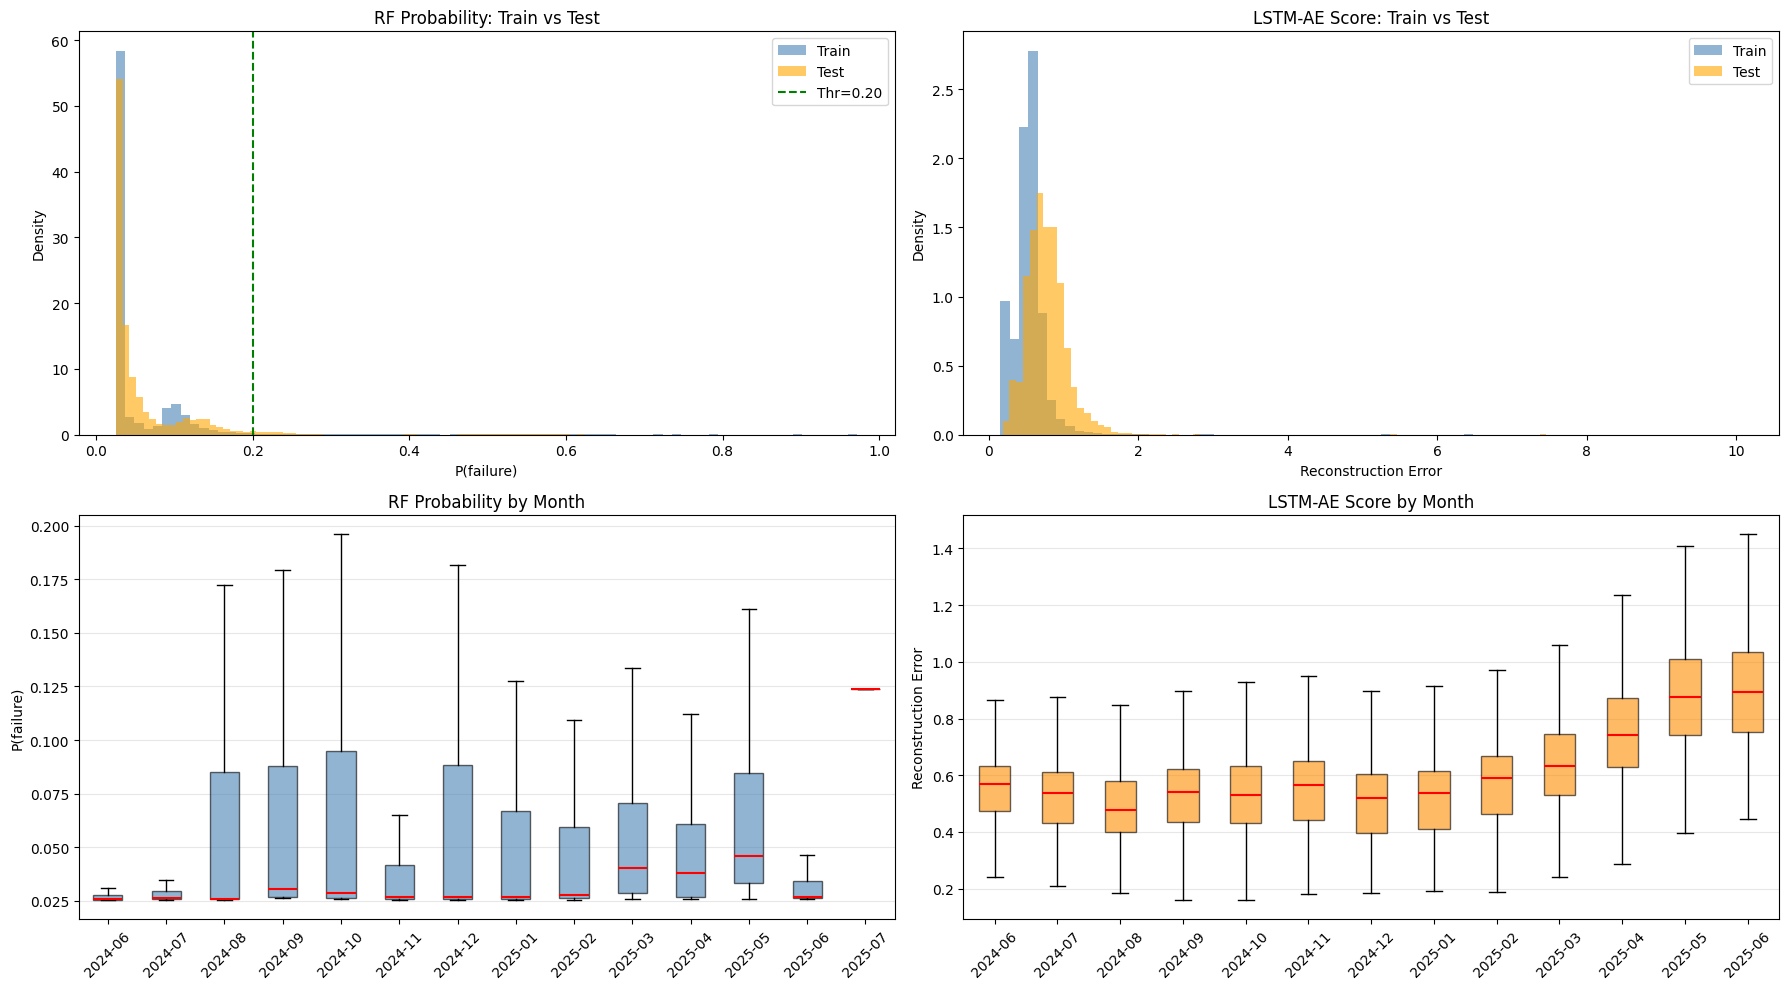


RF probability stats (train-period scores are largely IN-SAMPLE: the RF was fit on train data in NB02b):
  train: mean=0.0614, median=0.0268, std=0.0958, above_thr=1421 (3.43%)
  test: mean=0.0641, median=0.0366, std=0.0738, above_thr=879 (3.80%)

LSTM-AE score stats:
  train: mean=0.5388, median=0.5383, std=0.2598, p95=0.8257, p99=1.1794
  test: mean=0.7742, median=0.7459, std=0.2834, p95=1.2276, p99=1.5794


In [6]:
fig, axes = plt.subplots(2, 2, figsize=(18, 10))

# 3a. RF probability: train vs test
ax = axes[0, 0]
ax.hist(rf_all.loc[rf_all['split']=='train', 'prob'], bins=80, alpha=0.6, color='steelblue', label='Train', density=True)
ax.hist(rf_all.loc[rf_all['split']=='test', 'prob'], bins=80, alpha=0.6, color='orange', label='Test', density=True)
ax.axvline(RF_THR, color='green', linestyle='--', label=f'Thr={RF_THR:.2f}')
ax.set_xlabel('P(failure)')
ax.set_ylabel('Density')
ax.set_title('RF Probability: Train vs Test')
ax.legend()

# 3b. LSTM-AE score: train vs test
ax = axes[0, 1]
ax.hist(ae_all.loc[ae_all['split']=='train', 'score'], bins=80, alpha=0.6, color='steelblue', label='Train', density=True)
ax.hist(ae_all.loc[ae_all['split']=='test', 'score'], bins=80, alpha=0.6, color='orange', label='Test', density=True)
ax.set_xlabel('Reconstruction Error')
ax.set_ylabel('Density')
ax.set_title('LSTM-AE Score: Train vs Test')
ax.legend()

# 3c. RF monthly boxplot
ax = axes[1, 0]
rf_all['month'] = rf_all['window_end'].dt.to_period('M').astype(str)
months = sorted(rf_all['month'].unique())
data_by_month = [rf_all.loc[rf_all['month']==m, 'prob'].values for m in months]
bp = ax.boxplot(data_by_month, labels=months, patch_artist=True, showfliers=False,
                medianprops=dict(color='red', linewidth=1.5))
for patch in bp['boxes']:
    patch.set_facecolor('steelblue')
    patch.set_alpha(0.6)
ax.set_ylabel('P(failure)')
ax.set_title('RF Probability by Month')
ax.tick_params(axis='x', rotation=45)
ax.grid(True, alpha=0.3, axis='y')

# 3d. LSTM-AE monthly boxplot
ax = axes[1, 1]
ae_all['month'] = ae_all['window_end'].dt.to_period('M').astype(str)
ae_months = sorted(ae_all['month'].unique())
ae_data_by_month = [ae_all.loc[ae_all['month']==m, 'score'].values for m in ae_months]
bp = ax.boxplot(ae_data_by_month, labels=ae_months, patch_artist=True, showfliers=False,
                medianprops=dict(color='red', linewidth=1.5))
for patch in bp['boxes']:
    patch.set_facecolor('darkorange')
    patch.set_alpha(0.6)
ax.set_ylabel('Reconstruction Error')
ax.set_title('LSTM-AE Score by Month')
ax.tick_params(axis='x', rotation=45)
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

# Stats
print('\nRF probability stats (train-period scores are largely IN-SAMPLE: the RF was fit on train data in NB02b):')
for split in ['train', 'test']:
    s = rf_all.loc[rf_all['split']==split, 'prob']
    above = (s >= RF_THR).sum()
    print(f'  {split}: mean={s.mean():.4f}, median={s.median():.4f}, '
          f'std={s.std():.4f}, above_thr={above} ({100*above/len(s):.2f}%)')

print('\nLSTM-AE score stats:')
for split in ['train', 'test']:
    s = ae_all.loc[ae_all['split']==split, 'score']
    print(f'  {split}: mean={s.mean():.4f}, median={s.median():.4f}, '
          f'std={s.std():.4f}, p95={s.quantile(0.95):.4f}, p99={s.quantile(0.99):.4f}')

**Interpretation: train/test shift.** The LSTM-AE reconstruction error is clearly higher in the test period than in train, and keeps rising from about April 2025. This matches the baseline shift after 2025-04-17 reported by Steiner et al. (RAMS 2026) and the anomaly-rate drift found in NB04 (§1, §4.6).

Two consequences:
1. **Pooled comparisons are confounded.** Failure windows are concentrated in the test period (about 2.9% vs 1.3% of windows), so pooling train and test mixes "failure vs normal" with "test vs train". This is why NB03a reports effect sizes and correlations per period.
2. **RF train-period scores are largely in-sample** (the RF was trained on the train period), so train-vs-test comparisons of RF probabilities and RF hotspots are not like-for-like. Only the test period is a fair out-of-sample view.

## 4. Anomaly Hotspot Detection

Find sustained high-score periods — clusters of consecutive windows where anomaly scores stay elevated, regardless of failure labels. These represent "interesting" periods the models flag.

In [7]:
# ── RF hotspots: consecutive windows above threshold ──
rf_sorted = rf_all.sort_values('window_end').reset_index(drop=True)
above = (rf_sorted['prob'] >= RF_THR).astype(int)
grp = (above != above.shift()).cumsum()
hotspots_rf = []
for g, sub in rf_sorted[above == 1].groupby(grp[above == 1]):
    if len(sub) >= 3:  # at least 3 consecutive windows
        hotspots_rf.append({
            'start': sub['window_end'].min(),
            'end': sub['window_end'].max(),
            'n_windows': len(sub),
            'mean_prob': sub['prob'].mean(),
            'max_prob': sub['prob'].max(),
            'n_failure': sub['fail'].sum(),
            'split': sub['split'].iloc[0],
        })
hotspots_rf = pd.DataFrame(hotspots_rf)
hotspots_rf['duration_min'] = (hotspots_rf['end'] - hotspots_rf['start']).dt.total_seconds() / 60
hotspots_rf['has_failure'] = hotspots_rf['n_failure'] > 0

# ── LSTM-AE hotspots: above 90th percentile ──
ae_p90 = ae_all.loc[ae_all['split'] == 'train', 'score'].quantile(0.90)  # train-period p90, not dominated by the drifted test period
ae_sorted = ae_all.sort_values('window_end').reset_index(drop=True)
ae_above = (ae_sorted['score'] >= ae_p90).astype(int)
ae_grp = (ae_above != ae_above.shift()).cumsum()
hotspots_ae = []
for g, sub in ae_sorted[ae_above == 1].groupby(ae_grp[ae_above == 1]):
    if len(sub) >= 2:  # at least 2 consecutive sequences
        hotspots_ae.append({
            'start': sub['window_end'].min(),
            'end': sub['window_end'].max(),
            'n_seqs': len(sub),
            'mean_score': sub['score'].mean(),
            'max_score': sub['score'].max(),
            'n_failure': sub['fail'].sum(),
            'split': sub['split'].iloc[0],
        })
hotspots_ae = pd.DataFrame(hotspots_ae)
if len(hotspots_ae) > 0:
    hotspots_ae['duration_min'] = (hotspots_ae['end'] - hotspots_ae['start']).dt.total_seconds() / 60
    hotspots_ae['has_failure'] = hotspots_ae['n_failure'] > 0

print(f'RF hotspots (>=3 consecutive windows above thr={RF_THR:.2f}): {len(hotspots_rf)}')
print(f'  With actual failure: {hotspots_rf["has_failure"].sum()} | Without (potential false alarm clusters): {(~hotspots_rf["has_failure"]).sum()}')
print(f'  Train: {(hotspots_rf["split"]=="train").sum()} | Test: {(hotspots_rf["split"]=="test").sum()}')
print('  Note: train-period RF hotspots are largely in-sample (RF fit on train).')
print('  Failure definitions differ: RF fail = 6.2 h-shifted label; LSTM-AE fail = sequence overlaps a recorded failure.')
print(f'\nLSTM-AE hotspots (>=2 consecutive seqs above train-period p90={ae_p90:.3f}): {len(hotspots_ae)}')
if len(hotspots_ae) > 0:
    print(f'  With actual failure: {hotspots_ae["has_failure"].sum()} | Without: {(~hotspots_ae["has_failure"]).sum()}')

print(f'\n--- Top 15 RF hotspots by duration ---')
top_hs = hotspots_rf.nlargest(15, 'n_windows')[['start', 'end', 'n_windows', 'duration_min', 'mean_prob', 'n_failure', 'has_failure', 'split']]
print(top_hs.to_string(index=False))

RF hotspots (>=3 consecutive windows above thr=0.20): 186
  With actual failure: 27 | Without (potential false alarm clusters): 159
  Train: 124 | Test: 62
  Note: train-period RF hotspots are largely in-sample (RF fit on train).
  Failure definitions differ: RF fail = 6.2 h-shifted label; LSTM-AE fail = sequence overlaps a recorded failure.

LSTM-AE hotspots (>=2 consecutive seqs above train-period p90=0.714): 554
  With actual failure: 10 | Without: 544

--- Top 15 RF hotspots by duration ---
              start                 end  n_windows  duration_min  mean_prob  n_failure  has_failure split
2024-10-06 00:02:30 2024-10-08 10:22:30        147   3500.000000   0.801193        135         True train
2024-09-22 13:04:10 2024-09-24 02:06:40         88   2222.500000   0.561663          0        False train
2024-09-21 22:00:00 2024-09-22 07:20:00         75    560.000000   0.704683         58         True train
2024-06-27 15:27:30 2024-06-27 20:19:10         51    291.666667   0.234179 

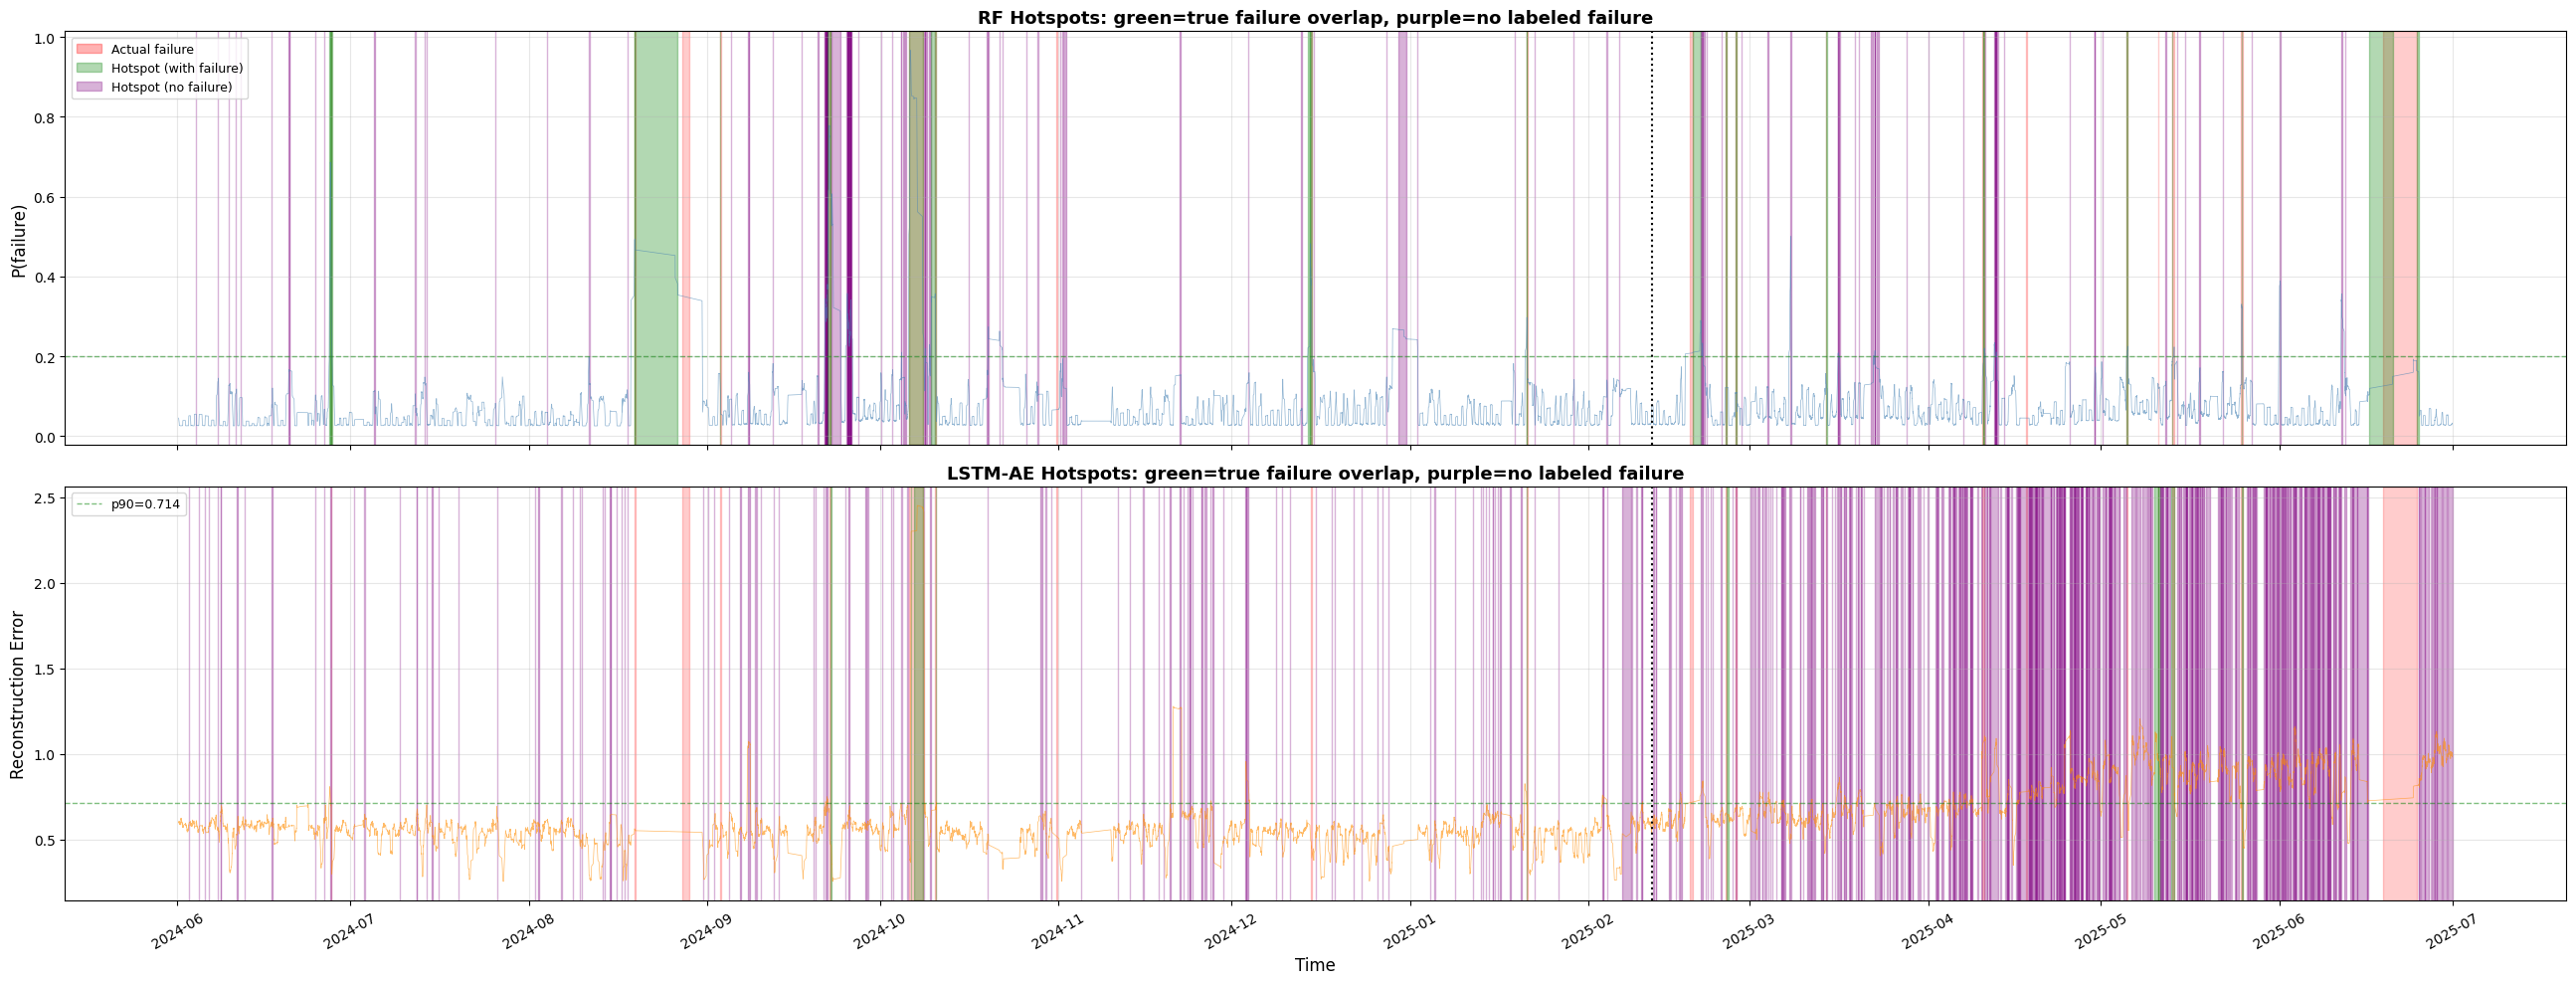

In [8]:
# ── Visualize hotspots on timeline ──
fig, axes = plt.subplots(2, 1, figsize=(26, 10), sharex=True)

# RF
ax = axes[0]
ax.plot(rf_roll.index, rf_roll.values, color='steelblue', linewidth=0.5, alpha=0.6)
ax.axhline(y=RF_THR, color='green', linestyle='--', linewidth=1, alpha=0.5)
ax.axvline(x=SPLIT_DATE, color='black', linestyle=':', linewidth=1.5)
for _, ev in fail_events_all.iterrows():
    ax.axvspan(ev['start'], ev['end'], alpha=0.2, color='red')
# Highlight hotspots
for _, hs in hotspots_rf.iterrows():
    color = 'green' if hs['has_failure'] else 'purple'
    ax.axvspan(hs['start'], hs['end'], alpha=0.3, color=color)
ax.set_ylabel('P(failure)', fontsize=12)
ax.set_title('RF Hotspots: green=true failure overlap, purple=no labeled failure', fontsize=13, fontweight='bold')
ax.legend(handles=[
    Patch(color='red', alpha=0.3, label='Actual failure'),
    Patch(color='green', alpha=0.3, label='Hotspot (with failure)'),
    Patch(color='purple', alpha=0.3, label='Hotspot (no failure)'),
], loc='upper left', fontsize=9)
ax.grid(True, alpha=0.3)

# LSTM-AE
ax = axes[1]
ax.plot(ae_roll.index, ae_roll.values, color='darkorange', linewidth=0.5, alpha=0.6)
ax.axhline(y=ae_p90, color='green', linestyle='--', linewidth=1, alpha=0.5, label=f'p90={ae_p90:.3f}')
ax.axvline(x=SPLIT_DATE, color='black', linestyle=':', linewidth=1.5)
for _, ev in fail_events_all.iterrows():
    ax.axvspan(ev['start'], ev['end'], alpha=0.2, color='red')
if len(hotspots_ae) > 0:
    for _, hs in hotspots_ae.iterrows():
        color = 'green' if hs['has_failure'] else 'purple'
        ax.axvspan(hs['start'], hs['end'], alpha=0.3, color=color)
ax.set_ylabel('Reconstruction Error', fontsize=12)
ax.set_title('LSTM-AE Hotspots: green=true failure overlap, purple=no labeled failure', fontsize=13, fontweight='bold')
ax.set_xlabel('Time', fontsize=12)
ax.legend(loc='upper left', fontsize=9)
ax.grid(True, alpha=0.3)

axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
axes[-1].xaxis.set_major_locator(mdates.MonthLocator())
plt.xticks(rotation=30, fontsize=10)
plt.tight_layout()
plt.show()

## 5. LSTM-AE Input Data: Standardization & Channel Checks

Verify z-score normalization quality and identify near-constant channels.

Near-constant channels (std < 0.01): 0


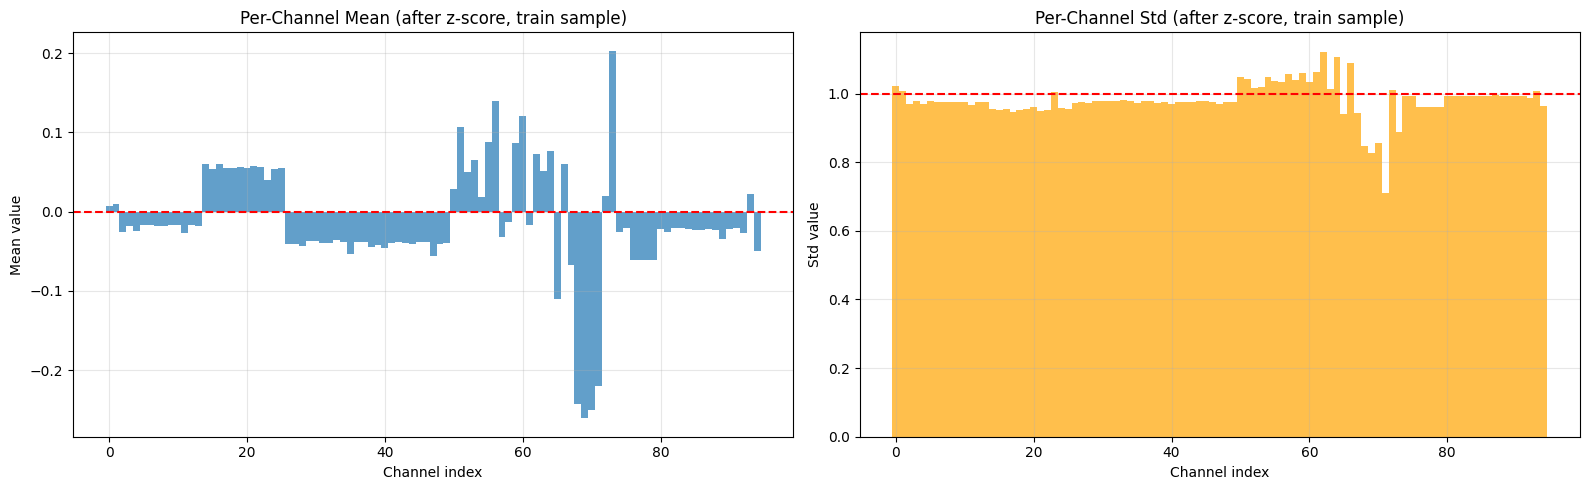


Channel mean: overall mean=-0.0126, std of means=0.0708
Channel std: overall mean=0.9811, std of stds=0.0518


In [9]:
# Documented sensor-group schema (MetroAT documentation, src/config.py). The two asset-history features
# (days since last failure / revision) are not sensors and get no group; they are left out of group summaries.
import sys
sys.path.insert(0, ROOT)
from src.config import SUBSYSTEMS
SENSOR_GROUP = {s: g for g, sensors in SUBSYSTEMS.items() for s in sensors}
NO_GROUP = 'no group (asset history)'
AGG_SUFFIXES = ('_active_s', '_min', '_max', '_mean', '_sum', '_flips')


def sensor_of(f):
    for suf in AGG_SUFFIXES:
        if f.endswith(suf):
            return f[:-len(suf)]
    return f


def get_subsystem(name):
    return SENSOR_GROUP.get(sensor_of(name), NO_GROUP)


# Load metadata
with open(os.path.join(OUT_DIR, 'unsupervised', 'metadata.json')) as f:
    meta = json.load(f)
UNSUP_CHANNELS = meta['channels']
channel_stats = meta['channel_stats']

# Check channel statistics
ch_info = pd.DataFrame([
    {'channel': ch, 'mean': channel_stats[ch]['mean'], 'std': channel_stats[ch]['std'],
     'subsystem': get_subsystem(ch)}
    for ch in UNSUP_CHANNELS
])

# Near-constant channels (very low std)
low_var = ch_info[ch_info['std'] < 0.01].sort_values('std')
print(f'Near-constant channels (std < 0.01): {len(low_var)}')
if len(low_var) > 0:
    print(low_var[['channel', 'mean', 'std', 'subsystem']].to_string(index=False))

# Load a small sample of train sequences to verify standardization
train_seqs = np.load(os.path.join(OUT_DIR, 'unsupervised', 'train.npy'), mmap_mode='r')
sample_idx = np.sort(np.random.RandomState(42).choice(len(train_seqs), size=min(500, len(train_seqs)), replace=False))
sample = np.asarray(train_seqs[sample_idx])  # 500 sequences spread over the train period

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Per-channel mean across sample
ax = axes[0]
ch_means = sample.mean(axis=(0, 1))  # mean over sequences and timesteps
ch_stds = sample.std(axis=(0, 1))
ax.bar(range(len(ch_means)), ch_means, alpha=0.7, width=1.0)
ax.set_xlabel('Channel index')
ax.set_ylabel('Mean value')
ax.set_title('Per-Channel Mean (after z-score, train sample)')
ax.axhline(0, color='red', linestyle='--')
ax.grid(True, alpha=0.3)

ax = axes[1]
ax.bar(range(len(ch_stds)), ch_stds, alpha=0.7, width=1.0, color='orange')
ax.set_xlabel('Channel index')
ax.set_ylabel('Std value')
ax.set_title('Per-Channel Std (after z-score, train sample)')
ax.axhline(1, color='red', linestyle='--')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

del train_seqs, sample; gc.collect()

# Summary
print(f'\nChannel mean: overall mean={ch_means.mean():.4f}, std of means={ch_means.std():.4f}')
print(f'Channel std: overall mean={ch_stds.mean():.4f}, std of stds={ch_stds.std():.4f}')
outlier_ch = np.where(np.abs(ch_means) > 0.5)[0]
if len(outlier_ch) > 0:
    print(f'Channels with |mean| > 0.5: {[(UNSUP_CHANNELS[i], f"{ch_means[i]:.3f}") for i in outlier_ch]}')

## 6. Daily and Time-of-Day RF Scores

Daily mean and maximum RF probability over the full period, and the mean probability by hour of day. Window counts, gaps and the failure rate by hour are in NB03a §5.

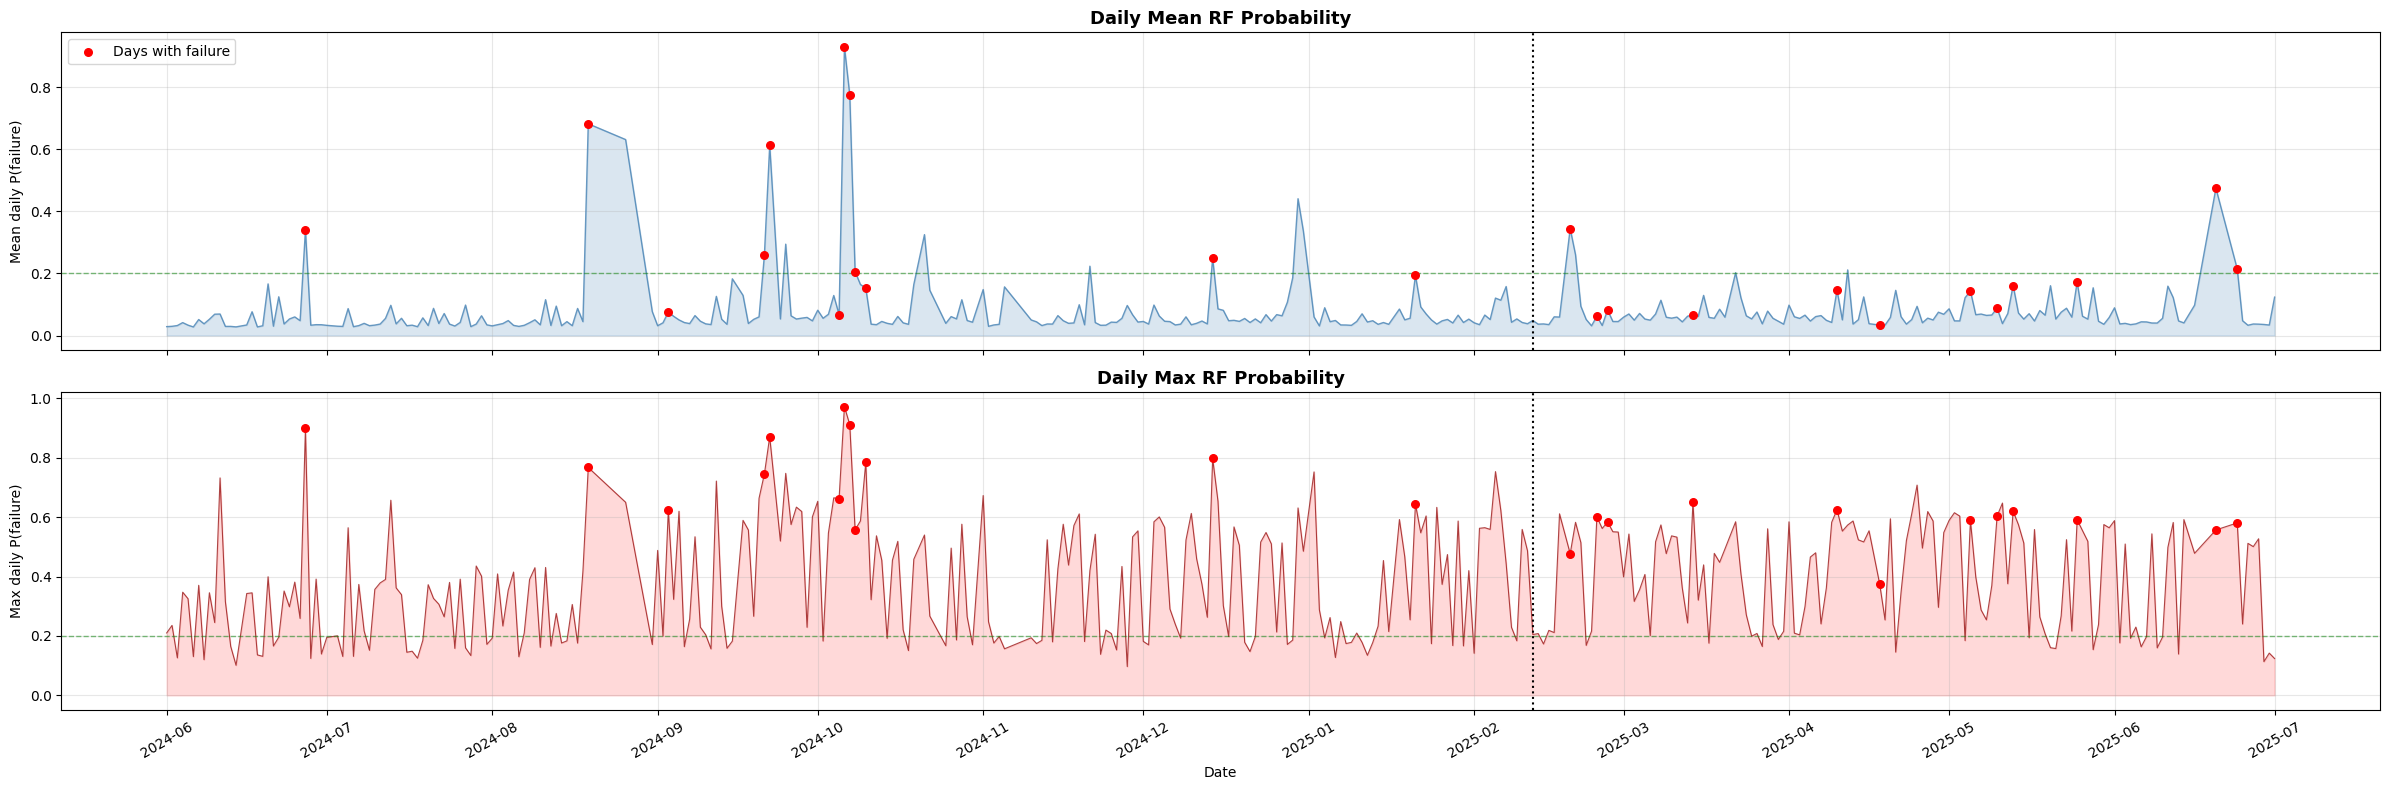

In [10]:
rf_all['date'] = rf_all['window_end'].dt.date
daily_rf = rf_all.groupby('date').agg(
    mean_prob=('prob', 'mean'),
    max_prob=('prob', 'max'),
    n_failure=('fail', 'sum')
).reset_index()
daily_rf['date'] = pd.to_datetime(daily_rf['date'])
fail_days = daily_rf[daily_rf['n_failure'] > 0]

fig, axes = plt.subplots(2, 1, figsize=(24, 8), sharex=True)

ax = axes[0]
ax.plot(daily_rf['date'], daily_rf['mean_prob'], color='steelblue', linewidth=1, alpha=0.8)
ax.fill_between(daily_rf['date'], 0, daily_rf['mean_prob'], alpha=0.2, color='steelblue')
ax.axhline(RF_THR, color='green', linestyle='--', linewidth=1, alpha=0.5)
ax.axvline(x=SPLIT_DATE, color='black', linestyle=':', linewidth=1.5)
ax.scatter(fail_days['date'], fail_days['mean_prob'], color='red', s=30, zorder=5, label='Days with failure')
ax.set_ylabel('Mean daily P(failure)')
ax.set_title('Daily Mean RF Probability', fontsize=13, fontweight='bold')
ax.legend(loc='upper left')
ax.grid(True, alpha=0.3)

ax = axes[1]
ax.plot(daily_rf['date'], daily_rf['max_prob'], color='darkred', linewidth=0.8, alpha=0.7)
ax.fill_between(daily_rf['date'], 0, daily_rf['max_prob'], alpha=0.15, color='red')
ax.axhline(RF_THR, color='green', linestyle='--', linewidth=1, alpha=0.5)
ax.axvline(x=SPLIT_DATE, color='black', linestyle=':', linewidth=1.5)
ax.scatter(fail_days['date'], fail_days['max_prob'], color='red', s=30, zorder=5)
ax.set_ylabel('Max daily P(failure)')
ax.set_title('Daily Max RF Probability', fontsize=13, fontweight='bold')
ax.set_xlabel('Date')
ax.grid(True, alpha=0.3)

axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
axes[-1].xaxis.set_major_locator(mdates.MonthLocator())
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

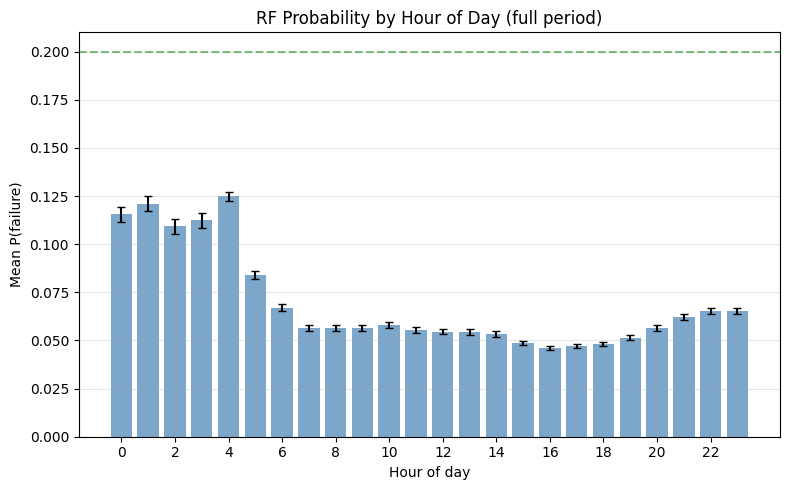

In [11]:
# ── RF probability by time of day ──
rf_all['hour'] = rf_all['window_end'].dt.hour
hourly = rf_all.groupby('hour')['prob'].agg(['mean', 'std', 'count'])

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(hourly.index, hourly['mean'], color='steelblue', alpha=0.7)
ax.errorbar(hourly.index, hourly['mean'], yerr=hourly['std']/np.sqrt(hourly['count']),
            fmt='none', color='black', capsize=3)
ax.axhline(RF_THR, color='green', linestyle='--', alpha=0.5)
ax.set_xlabel('Hour of day')
ax.set_ylabel('Mean P(failure)')
ax.set_title('RF Probability by Hour of Day (full period)')
ax.set_xticks(range(0, 24, 2))
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

In [12]:
# ── Summary ──
print('=' * 70)
print('BASELINE SCORE ANALYSIS SUMMARY (FULL PERIOD)')
print('=' * 70)

print(f'\nPeriod: {rf_all["window_end"].min().date()} to {rf_all["window_end"].max().date()}')
print(f'Train/Test split: {SPLIT_DATE.date()}')

print(f'\n--- Supervised (RF) ---')
print(f'Total windows: {len(rf_all):,} (train: {(rf_all["split"]=="train").sum():,}, test: {(rf_all["split"]=="test").sum():,})')
print(f'Failure windows: {rf_all["fail"].sum():,} ({100*rf_all["fail"].mean():.2f}%)')
print(f'Features: {len(feature_cols)}')
print(f'Threshold: {RF_THR:.3f}')
train_above = (rf_all.loc[rf_all['split']=='train', 'prob'] >= RF_THR).mean()
test_above = (rf_all.loc[rf_all['split']=='test', 'prob'] >= RF_THR).mean()
print(f'Windows above threshold: train={100*train_above:.2f}% (in-sample), test={100*test_above:.2f}% (out-of-sample)')

print(f'\n--- Unsupervised (LSTM-AE) ---')
print(f'Total sequences: {len(ae_all):,} (train: {(ae_all["split"]=="train").sum():,}, test: {(ae_all["split"]=="test").sum():,})')
print(f'Channels: {n_channels} | Seq length: {seq_len_sub} (subsampled from {SEQ_WINDOW_S}s)')
for split in ['train', 'test']:
    s = ae_all.loc[ae_all['split']==split, 'score']
    print(f'  {split} scores: mean={s.mean():.4f}, std={s.std():.4f}')

print(f'\n--- Failure Events ---')
print(f'Total: {len(fail_events_all)} (train: {(fail_events_all["period"]=="train").sum()}, test: {(fail_events_all["period"]=="test").sum()})')
for ft in fail_events_all['event_type'].unique():
    n = (fail_events_all['event_type'] == ft).sum()
    print(f'  {ft}: {n}')

print(f'\n--- Score Hotspots ---')
print(f'RF: {len(hotspots_rf)} (with failure: {hotspots_rf["has_failure"].sum()}, without: {(~hotspots_rf["has_failure"]).sum()})')
if len(hotspots_ae) > 0:
    print(f'LSTM-AE: {len(hotspots_ae)} (with failure: {hotspots_ae["has_failure"].sum()}, without: {(~hotspots_ae["has_failure"]).sum()})')

BASELINE SCORE ANALYSIS SUMMARY (FULL PERIOD)

Period: 2024-06-01 to 2025-07-01
Train/Test split: 2025-02-12

--- Supervised (RF) ---
Total windows: 64,522 (train: 41,375, test: 23,147)
Failure windows: 1,202 (1.86%)
Features: 340
Threshold: 0.200
Windows above threshold: train=3.43% (in-sample), test=3.80% (out-of-sample)

--- Unsupervised (LSTM-AE) ---
Total sequences: 15,246 (train: 9,872, test: 5,374)
Channels: 95 | Seq length: 350 (subsampled from 1402s)
  train scores: mean=0.5388, std=0.2598
  test scores: mean=0.7742, std=0.2834

--- Failure Events ---
Total: 21 (train: 10, test: 11)
  Brake System Failure: 13
  Leveling System Failure: 2
  Compressor Module Failure: 6

--- Score Hotspots ---
RF: 186 (with failure: 27, without: 159)
LSTM-AE: 554 (with failure: 10, without: 544)


## Traceability: Pipeline Position

**NB01 → NB02a → NB03a → NB04 → NB05** (clustering branch)  
**NB02a → NB02b → NB03b** (baseline branch; NB05 §4 and §7.3 compare the FCs with the baseline models)

### What this notebook provides
- Full-period RF / LSTM-AE score analysis, with the **train/test shift** made explicit (LSTM-AE error rises in the test period, consistent with RAMS 2026); train-period RF scores are in-sample
- Score hotspots (RF threshold; LSTM-AE train-period p90); counts in §4
- LSTM-AE input checks (standardization, near-constant channels)
- Not used by the clustering (NB04). Re-run after NB02b (Phase 2) replaces the models

### Outputs (`outputs/nb03b_artifacts/`)
- `anomaly_timeline_full.png`